In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import re
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy.optimize import curve_fit
from statsmodels.stats.outliers_influence import variance_inflation_factor
from collections import defaultdict

In [ ]:
def extract_function_name(filename):

    base = os.path.basename(filename)
    # Matching rules: Prefixed with sample_\d+_
    # Capture group content: Any character until _B is encountered, and optionally a closing parenthesis)
    # Suffix: Followed by an underscore or simply .pkl
    pattern = r'sample_\d+_(.*?_B\)?)(?=_|\.pkl)'
    match = re.search(pattern, base)

    if match:
        func = match.group(1)
        func = logical_name_to_symbol(func)
        return func
    return base.replace('.pkl', '')

def logical_name_to_symbol(name: str) -> str:
    return (
        name
        .replace("XNOR", "≡")
        .replace("XOR", "⊕")
        .replace("AND", "∧")
        .replace("OR", "∨")
        .replace("NOT_", "¬")
        .replace("(", "")
        .replace(")", "")
        .replace("_", " ")
    )


def load_data(folder_path):
    """
    Reads all PKL files in the folder, extracts fields, and combines them into a DataFrame.
    This unifies the data source for all downstream visualizations and analysis.
    """
    all_data = []
    if not os.path.exists(folder_path):
        print(f"Folder not found: {folder_path}")
        return pd.DataFrame()

    files = [f for f in os.listdir(folder_path) if f.endswith('.pkl')]
    print(f"Loading {len(files)} files from {folder_path}...")
    
    for filename in files:
        file_path = os.path.join(folder_path, filename)
        func_name = extract_function_name(filename) # Use extracted function name as Label

        try:
            with open(file_path, 'rb') as f:
                content = pickle.load(f)

            items = content if isinstance(content, list) else [content]

            for item in items:
                # === Key Field Extraction ===
                # Extracting all fields needed for both Performance plots and Strategy analysis
                strategy = item.get('strategy_type', 'none')

                # Note: We do not filter 'none' here yet, to preserve data integrity,
                # but we mark valid rows. Downstream functions will filter as needed.

                all_data.append({
                    'function_name': func_name,
                    'strategy_type': strategy,
                    'num_vars': item.get('num_vars'),
                    'num_trials': item.get('num_trials'),
                    'difficulty_ratio': item.get('difficulty_ratio', 0),
                    'trials_delta': item.get('trials_delta', 0),
                    'num_gt_var': item.get('num_gt_var', 2),
                    # Fields for Heatmap/Performance Analysis
                    'is_correct': item.get('is_correct', False),
                    'char_count': item.get('char_count', 0)
                })
        except Exception as e:
            print(f"Error loading {filename}: {e}")

    df = pd.DataFrame(all_data)

    # Preprocessing: Bin the Difficulty Ratio (for cleaner bar charts)
    if 'difficulty_ratio' in df.columns:
        # Round to nearest 0.1 to prevent x-axis fragmentation
        df['difficulty_ratio_bin'] = df['difficulty_ratio'].round(1)

    print(f"Loaded {len(df)} total samples.")
    return df

In [ ]:

### Used to analyze the strategy shift
#folder_path = "/content/drive/MyDrive/inference-time-scale-adaptation/analyzed_trajectory/analyzed_qwen3-thinking"
#folder_path = "/content/drive/MyDrive/inference-time-scale-adaptation/analyzed_trajectory/analyzed_deepseek-r1"


### used to plot basic statics like accuracy, char count, etc.
folder_path = "/content/drive/MyDrive/inference-time-scale-adaptation/model_trajectory/deepseek-r1"
#folder_path = "/content/drive/MyDrive/inference-time-scale-adaptation/model_trajectory/deepseek-v3"
#folder_path = "/content/drive/MyDrive/inference-time-scale-adaptation/model_trajectory/deepseek-v3-force"
df = load_data(folder_path)

Loading 10 files from /content/drive/MyDrive/infer_scale_reason/cogsci_results/deepseek-r1...
Loaded 3000 total samples.


PERFORMANCE VISUALIZATION Heatmaps & Line Plots for Accuracy/Chars

In [ ]:
def visualize_performance_metrics(df):
    """
    1. Heatmap: Shows global average data (aggregated across all functions).
    2. Line Plots: One line per file (logic function).

    Refactored to use the pre-loaded DataFrame but maintains exact plotting logic.
    """
    print("Generating Performance Heatmaps and Line Plots...")

    # Aggregation for global Heatmap
    global_map = defaultdict(lambda: {'acc': [], 'chars': []})
    # Aggregation for Line Plots: {func_name: {n_var: {'acc':[], 'chars':[]}}}
    func_var_map = defaultdict(lambda: defaultdict(lambda: {'acc': [], 'chars': []}))
    # {func_name: {n_trial: {'acc':[], 'chars':[]}}}
    func_trial_map = defaultdict(lambda: defaultdict(lambda: {'acc': [], 'chars': []}))

    unique_vars = set()
    unique_trials = set()

    for _, row in df.iterrows():
        func_name, v, t, acc, chars = row['function_name'], row['num_vars'], row['num_trials'], 1 if row['is_correct'] else 0, row['char_count']
        unique_vars.add(v); unique_trials.add(t)
        global_map[(v, t)]['acc'].append(acc)
        global_map[(v, t)]['chars'].append(chars)
        func_var_map[func_name][v]['acc'].append(acc)
        func_var_map[func_name][v]['chars'].append(chars)
        func_trial_map[func_name][t]['acc'].append(acc)
        func_trial_map[func_name][t]['chars'].append(chars)

    sorted_vars = sorted(list(unique_vars))
    sorted_trials = sorted(list(unique_trials))
    sorted_funcs = sorted(list(func_var_map.keys()))
    colors = plt.cm.tab10(np.linspace(0, 1, len(sorted_funcs)))

    def save_heatmap(matrix, title, filename, cmap, is_acc=True):
        plt.figure(figsize=(9, 7))
        ax = plt.gca()
        im = ax.imshow(matrix, origin='lower', cmap=cmap, aspect='auto', interpolation='nearest')
        ax.set_xlabel('Number of Variables', fontsize=16)
        ax.set_ylabel('Number of Trials', fontsize=16)
        ax.set_xticks(np.arange(len(sorted_vars)))
        ax.set_xticklabels(sorted_vars)
        ax.set_yticks(np.arange(len(sorted_trials)))
        ax.set_yticklabels(sorted_trials)

        for i in range(len(sorted_trials)):
            for j in range(len(sorted_vars)):
                val = matrix[i, j]
                if not np.isnan(val):
                    color = "white" if (is_acc and (val < 0.3 or val > 0.8)) or (not is_acc and val > np.nanmean(matrix)*1.5) else "black"
                    label = f"{val:.2f}" if is_acc else f"{int(val)}"
                    ax.text(j, i, label, ha="center", va="center", color=color, fontsize=10, fontweight='bold')

        cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
        cbar.set_label(title, fontsize=14)

        cbar.ax.tick_params(labelsize=12)
        plt.tight_layout()
        plt.savefig(f'{filename}.svg', format='svg',bbox_inches='tight', transparent=True)
        plt.show()
        #plt.close()

    def save_line_plot(data_map, x_label, y_label, filename, metric='acc', is_var=True):
        plt.figure(figsize=(7, 4))
        ax = plt.gca()
        for idx, func in enumerate(sorted_funcs):
            
            x_vals = sorted(data_map[func].keys())
            y_vals = [np.mean(data_map[func][x][metric]) for x in x_vals]

            marker = 'o' if metric == 'acc' else 's'
            linestyle = '-' if metric == 'acc' else '--'
            ax.plot(x_vals, y_vals, marker=marker, linestyle=linestyle, linewidth=2.5,
                    markersize=8, label=func, color=colors[idx])

        ax.set_xlabel(x_label, fontsize=16)
        ax.set_ylabel(y_label, fontsize=16)
        ax.tick_params(axis='both', labelsize=14)
        if metric == 'acc': ax.set_ylim(-0.05, 1.05)

        plt.grid(visible=True, axis='y', linestyle='--', alpha=0.3)

        plt.gca().spines['top'].set_visible(False)
        plt.gca().spines['right'].set_visible(False)
        
        ax.legend(loc='best', fontsize=13)
        plt.tight_layout()
        plt.savefig(f'{filename}.svg', format='svg', bbox_inches='tight', transparent=True)
        plt.show()
        #plt.close()

    acc_matrix = np.zeros((len(sorted_trials), len(sorted_vars)))
    char_matrix = np.zeros((len(sorted_trials), len(sorted_vars)))
    for r_idx, t in enumerate(sorted_trials):
        for c_idx, v in enumerate(sorted_vars):
            stats = global_map.get((v, t))
            acc_matrix[r_idx, c_idx] = np.mean(stats['acc']) if stats else np.nan
            char_matrix[r_idx, c_idx] = np.mean(stats['chars']) if stats else np.nan

    save_heatmap(acc_matrix, "Accuracy", "heatmap_accuracy", "RdYlGn", True)
    save_heatmap(char_matrix, "Char Count", "heatmap_char_count", "YlGnBu", False)

    # 2. 保存四个 Line Plots
    save_line_plot(func_var_map, "Number of Candidate Variable", "Mean Accuracy", "line_acc_vs_vars", 'acc')
    save_line_plot(func_var_map, "Number of Candidate Variable", "Avg Character Count", "line_char_vs_vars", 'chars')
    save_line_plot(func_trial_map, "Number of Trials", "Mean Accuracy", "line_acc_vs_trials", 'acc')
    save_line_plot(func_trial_map, "Number of Trials", "Avg Character Count", "line_char_vs_trials", 'chars')

    print("All 6 plots have been saved as separate .svg files.")

Generating Performance Heatmaps and Line Plots...


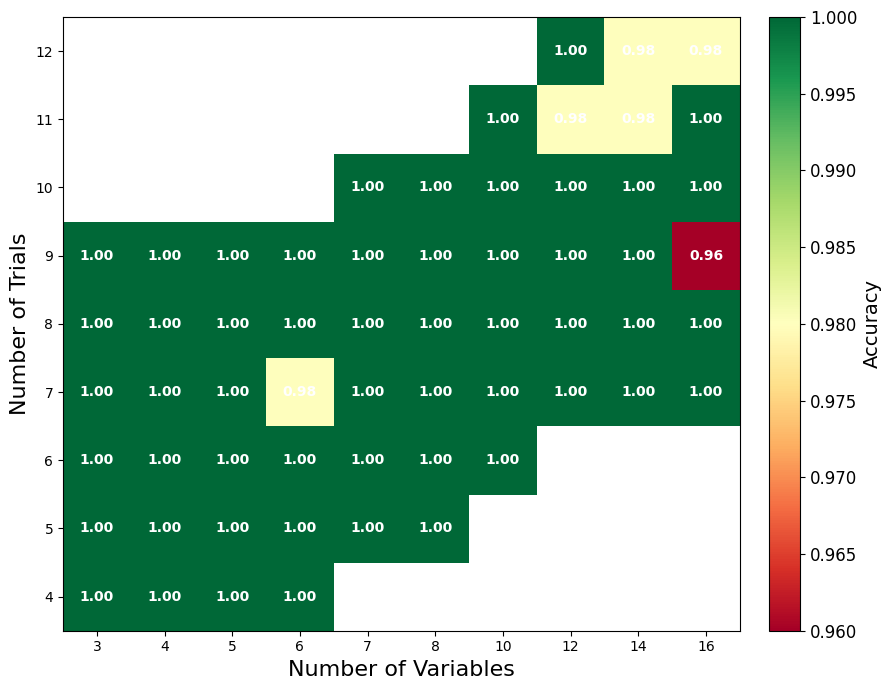

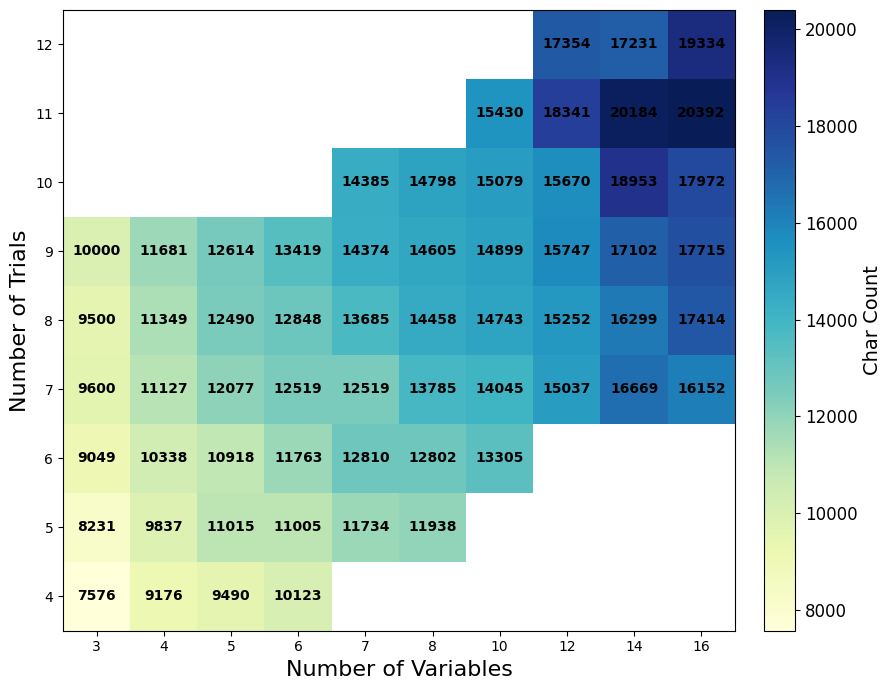

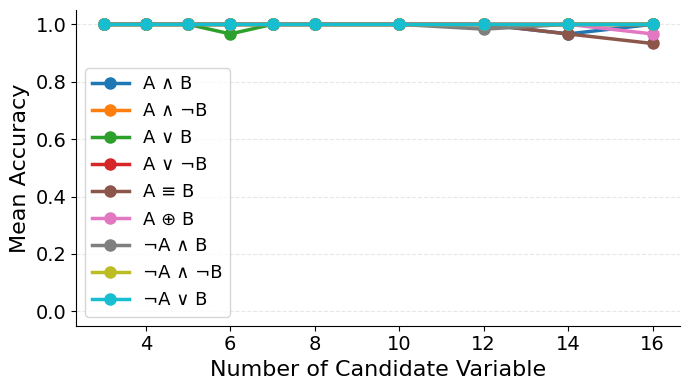

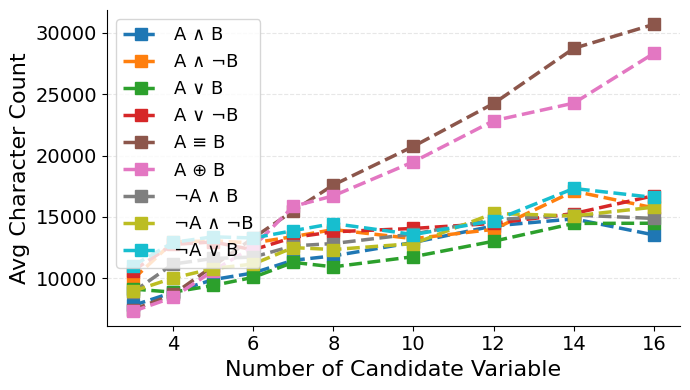

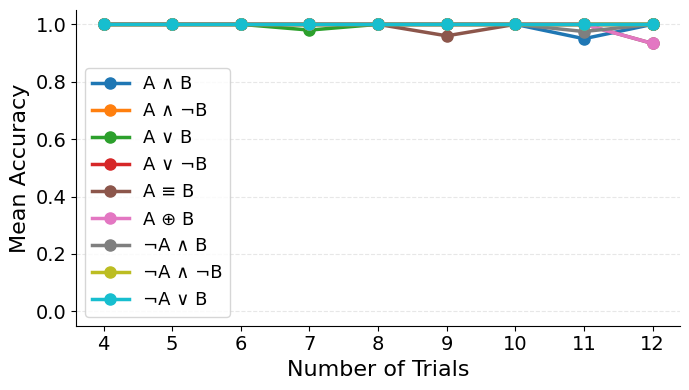

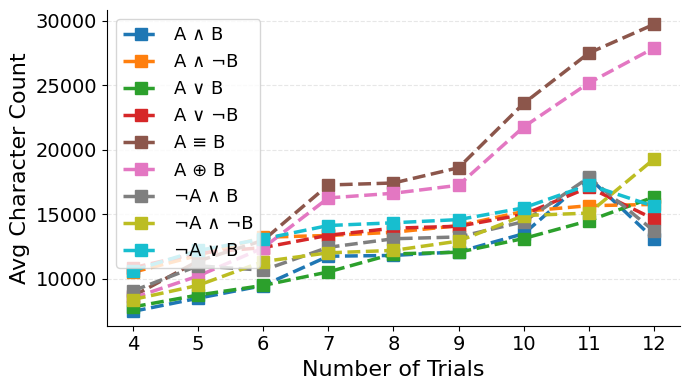

All 6 plots have been saved as separate .svg files.


In [15]:
visualize_performance_metrics(df)

STRATEGY DISTRIBUTION VISUALIZATION (Stacked Bar Charts & Probability Lines)

In [ ]:
from matplotlib.gridspec import GridSpec
from scipy import stats

def get_bootstrap_ci(data, n_iterations=1000, ci=95):
    if len(data) == 0:
        return np.nan, np.nan

    boot_means = []
    for _ in range(n_iterations):
        
        sample = np.random.choice(data, size=len(data), replace=True)
        boot_means.append(np.mean(sample))

    lower_bound = np.percentile(boot_means, (100 - ci) / 2)
    upper_bound = np.percentile(boot_means, 100 - (100 - ci) / 2)
    return lower_bound, upper_bound

def plot_general_distribution(df, x_col, x_label):
    """
    Stacked Bar Chart: Shows the overall proportion of Elimination vs Permutation.
    """
    if x_col not in df.columns:
        return

    plt.figure(figsize=(10, 5))

    # Pivot: Index=X, Columns=Strategy, Values=Count
    pivot_df = df.groupby([x_col, 'strategy_type']).size().unstack(fill_value=0)

    # Normalize to 100%
    pivot_df = pivot_df.div(pivot_df.sum(axis=1), axis=0)

    # Plot
    # colormap: 'RdYlBu' or 'coolwarm' suitable for comparison
    ax = pivot_df.plot(kind='bar', stacked=True, colormap='coolwarm', figsize=(10, 6), width=0.85, alpha=0.9,fontsize=16)

    #plt.title(f'Overall Strategy Distribution by {x_label}', fontsize=16, fontweight='bold')
    plt.xlabel(x_label, fontsize=16)
    plt.ylabel('Proportion of Elimination', fontsize=16)
    plt.legend(title='Strategy', loc='lower right', fontsize=15)

    # X-axis label optimization
    if len(pivot_df) > 15:
        # If too many bars, show only partial labels
        n = 2 if len(pivot_df) < 30 else 5
        for i, label in enumerate(ax.xaxis.get_ticklabels()):
            if i % n != 0:
                label.set_visible(False)
        plt.xticks(rotation=0)
    else:
        plt.xticks(rotation=0)

    plt.grid(axis='y', linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.show()

def plot_heatmap_with_marginals(df, x_col, y_col):
    """
    Heatmap with Marginal Line Plots:
    """
    if x_col not in df.columns or y_col not in df.columns:
        return

    df_plot = df.copy()
    df_plot['is_elimination'] = (df_plot['strategy_type'] == 'elimination').astype(int)

    heatmap_data = df_plot.groupby([y_col, x_col])['is_elimination'].mean().unstack()
    heatmap_data = heatmap_data.sort_index(ascending=False)

    x_marginal = heatmap_data.mean(axis=0)  
    y_marginal = heatmap_data.mean(axis=1)  

    fig = plt.figure(figsize=(13, 11))
    gs = GridSpec(2, 2, width_ratios=[12, 1], height_ratios=[1, 11], hspace=0.05, wspace=0.05)

    ax_top = fig.add_subplot(gs[0, 0])
    ax_top.plot(range(len(x_marginal)), x_marginal, marker='o', color='#d73027', linewidth=2)
    ax_top.set_xticks([]) # 隐藏刻度，与热力图对齐
    ax_top.set_ylim(0, 1)
    ax_top.set_ylabel('Mean', fontsize=18)
    ax_top.grid(axis='y', linestyle='--', alpha=0.3)
    #ax_top.spines['top'].set_visible(False)
    #ax_top.spines['right'].set_visible(False)

    ax_main = fig.add_subplot(gs[1, 0])
    sns.heatmap(
        heatmap_data,
        ax=ax_main,
        cmap='coolwarm_r',
        annot=True,
        fmt=".2f",
        linewidths=.5,
        cbar=False, 
        annot_kws={"size": 18}
    )
    ax_main.set_xlabel("Number of Variables", fontsize=20)
    ax_main.set_ylabel("Number of Trials", fontsize=20)
    plt.xticks(fontsize=17)
    plt.yticks(fontsize=17, rotation=0)

    ax_right = fig.add_subplot(gs[1, 1])

    y_coords = range(len(y_marginal))

    ax_right.plot(
        y_marginal,
        y_coords[::-1],
        marker='o',
        color='#4575b4',
        linewidth=2.5,
        markersize=6
    )

    ax_right.set_yticks([])
    ax_right.set_xlim(0.5, 1) 
    ax_right.set_xlabel('Mean', fontsize=18)
    ax_right.grid(axis='x', linestyle='--', alpha=0.3)
    #ax_right.spines['top'].set_visible(False)
    #ax_right.spines['right'].set_visible(False)
    #ax_right.spines['left'].set_visible(False) 

    cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.55]) # [left, bottom, width, height]
    sm = plt.cm.ScalarMappable(cmap='coolwarm_r', norm=plt.Normalize(vmin=0, vmax=1))
    cbar = fig.colorbar(sm, cax=cbar_ax)
    cbar.set_label('Proportion of Elimination', fontsize=18)
    cbar.ax.tick_params(labelsize=16)

    #plt.suptitle(f'Elimination Strategy Analysis: {x_col} vs {y_col}', fontsize=18, y=0.96)
    plt.savefig('heatmap.svg', format='svg', bbox_inches='tight', transparent=True)
    plt.show()

def plot_function_comparison(df, x_col, x_label):
    df_plot = df.copy()
    df_plot[x_col] = pd.to_numeric(df_plot[x_col], errors='coerce')
    df_plot.dropna(subset=[x_col, 'strategy_type'], inplace=True)
    df_plot['is_elimination'] = (df_plot['strategy_type'] == 'elimination').astype(int)

    plt.figure(figsize=(11, 5))
    funcs = df_plot['function_name'].unique()
    funcs = sorted(list(funcs))
    palette = plt.cm.tab10(np.linspace(0, 1, len(funcs)))

    for i, func in enumerate(funcs):
        color = palette[i]
        subset = df_plot[df_plot['function_name'] == func]

        stats = subset.groupby(x_col)['is_elimination'].apply(list).reset_index()
        stats['mean'] = stats['is_elimination'].apply(np.mean)

        cis = stats['is_elimination'].apply(get_bootstrap_ci)
        stats['ci_lower'] = [c[0] for c in cis]
        stats['ci_upper'] = [c[1] for c in cis]

        stats = stats.sort_values(by=x_col)

        plt.fill_between(
            stats[x_col], stats['ci_lower'], stats['ci_upper'],
            color=color, alpha=0.15, label='_nolegend_'
        )

        plt.plot(
            stats[x_col], stats['mean'],
            marker='o', markersize=6, linewidth=2.5,
            color=color, label=func, alpha=0.9
        )

    plt.grid(visible=True, axis='y', linestyle='--', alpha=0.3)

    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)

    plt.ylim(-0.05, 1.05)
    plt.xticks(fontsize=17) 
    plt.yticks(fontsize=17)
    plt.xlabel(x_label, fontsize=20)
    plt.ylabel('Proportion of Elimination', fontsize=20)

    #plt.legend(title='Logic Function', loc='best', frameon=True, fontsize=13, title_fontsize=13)
    #plt.legend(title='Logic Function', loc='upper left', bbox_to_anchor=(1, 1), frameon=True, fontsize=17, title_fontsize=17)

    #plt.grid(True, linestyle='--', alpha=0.3)
    plt.savefig('comparison.svg', format='svg', bbox_inches='tight', transparent=True)
    plt.tight_layout()
    plt.show()

Filtered for analysis: 2999 samples (Elimination/Permutation).


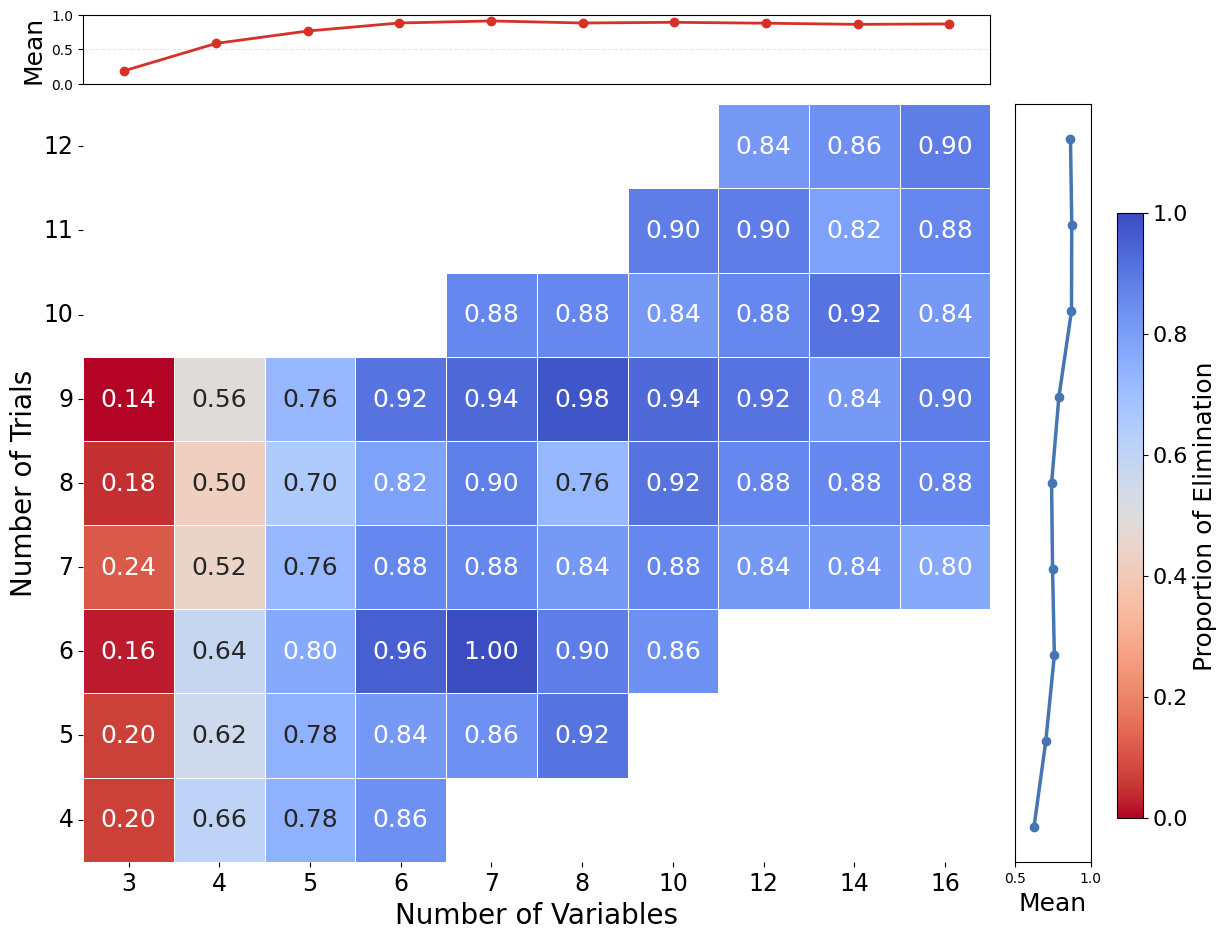


Plotting General Strategy Distributions...

Plotting Function Comparisons...


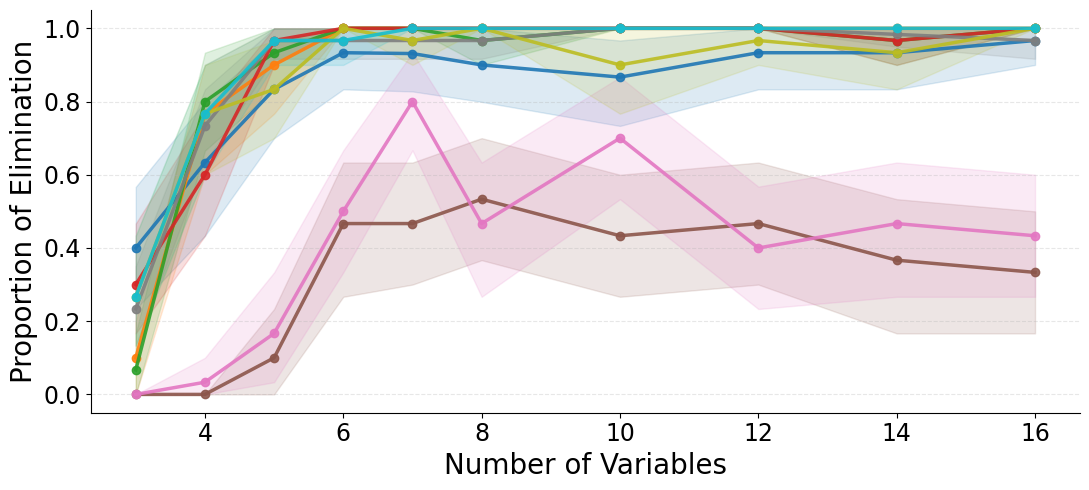

In [ ]:
valid_strategies = ['elimination', 'permutation']
df_analysis = df[df['strategy_type'].isin(valid_strategies)].copy()
print(f"Filtered for analysis: {len(df_analysis)} samples (Elimination/Permutation).")

plot_heatmap_with_marginals(df_analysis, 'num_vars', 'num_trials')

# General Strategy Distributions
print("\nPlotting General Strategy Distributions...")
#plot_general_distribution(df_analysis, 'num_vars', 'Number of Candidate Variable')
#plot_general_distribution(df_analysis, 'num_trials', 'Number of Trials')
#plot_general_distribution(df_analysis, 'difficulty_ratio_bin', 'Difficulty Ratio')

# Per-Function Line Plots
print("\nPlotting Function Comparisons...")
plot_function_comparison(df_analysis, 'num_vars', 'Number of Variables')
#plot_function_comparison(df_analysis, 'num_trials', 'Number of Trials')
#plot_function_comparison(df_analysis, 'difficulty_ratio_bin', 'Difficulty Ratio')

STATISTICAL ANALYSIS & MODELING (AIC, VIF, Regression, Marginal Effects)

In [ ]:
import statsmodels.formula.api as smf
from statsmodels.iolib.summary2 import summary_col
from statsmodels.stats.outliers_influence import variance_inflation_factor

def run_model_selection(df):
    df = df.copy()

    df['log_n_combos'] = np.log(df['num_vars'] * (df['num_vars'] - 1) / 2)
    df['log_rho'] = np.log((2**df['num_trials']) / (df['num_vars'] * (df['num_vars'] - 1) / 2))
    df['is_elimination'] = (df['strategy_type'] == 'elimination').astype(int)

    means = {
        'log_n': df['log_n_combos'].mean(),
        'trials': df['num_trials'].mean(),
        'log_rho': df['log_rho'].mean()
    }

    df['log_n_c'] = df['log_n_combos'] - means['log_n']
    df['trials_c'] = df['num_trials'] - means['trials']
    df['log_rho_c'] = df['log_rho'] - means['log_rho']

    models = {
        'elimination ~ log(hypothesis space)': smf.logit("is_elimination ~ log_n_c", data=df).fit(disp=0),
        'elimination ~ n_trials':  smf.logit("is_elimination ~ trials_c", data=df).fit(disp=0),
        'elimination ~ information ratio':     smf.logit("is_elimination ~ log_rho_c", data=df).fit(disp=0),
        'elimination ~ log(hypothesis space) + n_trials':   smf.logit("is_elimination ~ log_n_c + trials_c", data=df).fit(disp=0),
        'elimination ~ log(hypothesis space) * n_trials': smf.logit("is_elimination ~ log_n_c * trials_c", data=df).fit(disp=0)
    }

    results = []
    for name, m in models.items():
        results.append({
            "Model": name,
            "AIC": m.aic,
            "Pseudo R2": m.prsquared,
            "Log-Likelihood": m.llf
        })
        print(m.summary())

    summary_df = pd.DataFrame(results).sort_values("AIC")

    print("\n" + "="*60)
    print("MODEL SELECTION TOURNAMENT (All Centered)")
    print("="*60)
    print(summary_df.to_string(index=False))

    winner_model = models['elimination ~ log(hypothesis space) * n_trials']
    print("\n" + "="*60)
    print("WINNING MODEL DETAILS (The Interaction Hypothesis)")
    print("="*60)
    print(winner_model.summary())


    return winner_model, df

def plot_rationality_heatmap(model, df, n_limits=(2, 24), t_limits=(3, 16)):
    """
    Fixed-range heatmap analysis
    n_limits: The range of physical variable N, such as (3, 16)
    t_limits: The range of the number of experiments T, such as (4, 12)
    """

    # X-axis range: from ln(C(n_min, 2)) to ln(C(n_max, 2))
    x_min = np.log(n_limits[0] * (n_limits[0] - 1) / 2)
    x_max = np.log(n_limits[1] * (n_limits[1] - 1) / 2)

    x_grid = np.linspace(x_min, x_max, 100)
    y_grid = np.linspace(t_limits[0], t_limits[1], 100)
    X_mesh, Y_mesh = np.meshgrid(x_grid, y_grid)

    log_n_mean = np.log(df['num_vars']*(df['num_vars']-1)/2).mean()
    t_mean = df['num_trials'].mean()

    X_centered = X_mesh - log_n_mean
    Y_centered = Y_mesh - t_mean

    c = model.params
    # Logit = b0 + b1*log_N + b2*T + b3*(log_N * T)
    logit = c[0] + c[1]*X_centered + c[2]*Y_centered + c[3]*(X_centered * Y_centered)
    prob = 1 / (1 + np.exp(-logit))

    plt.figure(figsize=(10, 8))

    cp = plt.contourf(X_mesh, Y_mesh, prob, levels=24, cmap='coolwarm_r', alpha=1)
    cbar = plt.colorbar(cp)
    cbar.set_label('Pr(Strategy = Elimination)', rotation=270, labelpad=20, fontsize=16)
    cbar.ax.tick_params(labelsize=16)

    plt.contour(X_mesh, Y_mesh, prob, levels=[0.5], colors='black', linestyles='--')

    actual_log_n = np.log(df['num_vars']*(df['num_vars']-1)/2)
    plt.scatter(actual_log_n, df['num_trials'], alpha=0.2, color='gray', s=20, label='Actual Experiments')

    trajectory = df.groupby('num_vars').agg({'num_trials': 'mean'}).reset_index()
    trajectory = trajectory[(trajectory['num_vars'] >= n_limits[0]) & (trajectory['num_vars'] <= n_limits[1])]
    traj_log_n = np.log(trajectory['num_vars']*(trajectory['num_vars']-1)/2)

    plt.plot(traj_log_n, trajectory['num_trials'], color='black', marker='o',
             linewidth=5, markersize=12, alpha=0.2, zorder=3)
    plt.plot(traj_log_n, trajectory['num_trials'], color='white', marker='o',
             linewidth=2, markersize=7, label='Experimental Path (Mean T)', zorder=4)

    plt.xlim(x_min+0.5, x_max)
    plt.ylim(t_limits[0], t_limits[1])
    plt.xticks(fontsize=17)
    plt.yticks(fontsize=17)

    #plt.title("Fitted Landscape of the Trade-off Between Trials and Hypothesis Space", fontsize=14, fontweight='bold')
    plt.ylabel("Inference Resources (Number of Trials T)", fontsize=18)
    plt.xlabel(r"Log Hypothesis Space Size $\log \binom{n}{2}$", fontsize=18)
    jitter = 0
    
    for i, row in trajectory.iterrows():
        if i == 9:
          jitter = 0.2
        elif i == 7:
          jitter = -0.2
        elif i == 4:
          jitter = -0.1
        else:
          jitter = 0
        plt.text(np.log(row['num_vars']*(row['num_vars']-1)/2) + jitter, row['num_trials'] + 0.5,
                 f"N={int(row['num_vars'])}", fontsize=14, ha='center',fontweight='bold')

    plt.legend(loc='lower right', frameon=True, fontsize=14)
    plt.tight_layout()
    #plt.savefig('landscape.svg', format='svg', bbox_inches='tight', transparent=True)
    plt.savefig('landscape.pdf', format='pdf', bbox_inches='tight', transparent=True)
    plt.show()

                           Logit Regression Results                           
Dep. Variable:         is_elimination   No. Observations:                 2999
Model:                          Logit   Df Residuals:                     2997
Method:                           MLE   Df Model:                            1
Date:                Tue, 10 Feb 2026   Pseudo R-squ.:                  0.1470
Time:                        08:55:24   Log-Likelihood:                -1380.9
converged:                       True   LL-Null:                       -1618.8
Covariance Type:            nonrobust   LLR p-value:                1.766e-105
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.4647      0.053     27.529      0.000       1.360       1.569
log_n_c        0.8948      0.045     19.761      0.000       0.806       0.984
                           Logit Regression Results 

/tmp/ipython-input-520929136.py:92: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  logit = c[0] + c[1]*X_centered + c[2]*Y_centered + c[3]*(X_centered * Y_centered)


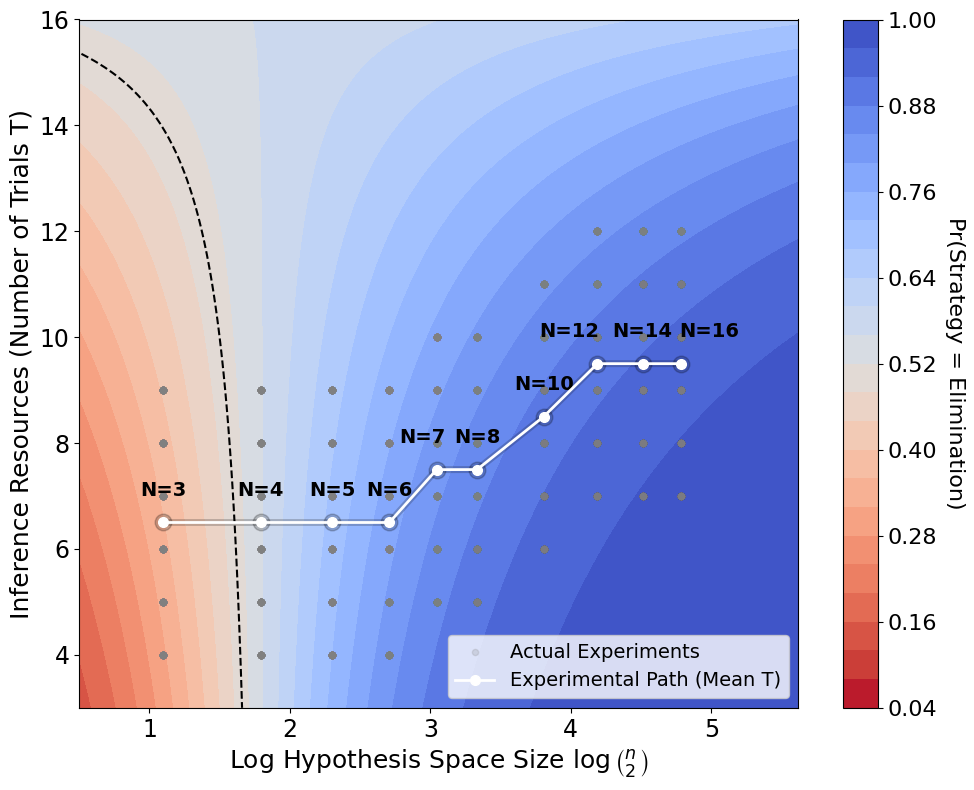

In [ ]:
winner_model, df_centered = run_model_selection(df_analysis)
plot_rationality_heatmap(winner_model, df_centered)

# UI to inspect the pkl flie

In [ ]:
import pickle
import ipywidgets as widgets
from IPython.display import display, clear_output

class SimplePKLViewer:
    def __init__(self, file_path):
        # 1. 直接读取整个列表
        try:
            with open(file_path, 'rb') as f:
                self.data = pickle.load(f)
        except Exception as e:
            print(f"读取文件失败: {e}")
            return

        self.current_idx = 0
        self.total = len(self.data)

        self.output = widgets.Output()
        self.info_label = widgets.Label()

        self.btn_back = widgets.Button(description="上一条", icon='arrow-left')
        self.btn_next = widgets.Button(description="下一条", icon='arrow-right')
        self.jump_input = widgets.BoundedIntText(value=1, min=1, max=self.total, layout={'width': '80px'})
        self.jump_btn = widgets.Button(description="跳转", layout={'width': '60px'})

        self.btn_back.on_click(lambda b: self.move(-1))
        self.btn_next.on_click(lambda b: self.move(1))
        self.jump_btn.on_click(lambda b: self.jump())

    def move(self, step):
        new_idx = self.current_idx + step
        if 0 <= new_idx < self.total:
            self.current_idx = new_idx
            self.show()

    def jump(self):
        self.current_idx = self.jump_input.value - 1
        self.show()

    def show(self):
        with self.output:
            clear_output(wait=True)
            item = self.data[self.current_idx]

            content = item.get('llm_raw_response', str(item))
            gt = item.get('ground_truth', 'N/A')

            print(f"--- Index: {self.current_idx} | Ground Truth: {gt} ---")
            print("-" * 50)
            print(content)

        self.info_label.value = f"进度: {self.current_idx + 1} / {self.total}"
        self.jump_input.value = self.current_idx + 1

    def run(self):
        nav_bar = widgets.HBox([self.btn_back, self.btn_next, widgets.Label("  Go to:"), self.jump_input, self.jump_btn])
        ui = widgets.VBox([self.info_label, nav_bar, self.output])
        display(ui)
        self.show()

# ================= How to use =================
# Fill in the path of the pkl file you want to view specifically
FILE_PATH = "/content/drive/MyDrive/infer_scale_reason/cogsci_results/qwen3-instruct/2_vars_adaptive_sample_5_A_XOR_B_Qwen3-Next-Instruct.pkl"
viewer = SimplePKLViewer(FILE_PATH)
viewer.run()